In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.config import load_config
from src.evaluation.comparison import compare, load_records

In [ ]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()), Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)   # so relative paths in src/ resolve from the repo root

In [4]:
# one row per model, mean and spread across folds
fcfg = load_config("forecast_config")
primary = fcfg["primary_metric"]
records = load_records()
table = compare(records, primary)
table.drop(columns="run_id").round(4)

,model,wape_mean,wape_std,mae_mean,mae_std,rmse_mean,rmse_std,smape_mean,smape_std,bias_mean,bias_std,fit_seconds,wape_vs_seasonal_naive_pct
0,catboost,0.7133,0.0386,2.1027,0.0520,2.5364,0.0730,87.1975,4.2266,0.0677,0.0973,1.769,-27.7646
1,lightgbm,0.7135,0.0380,2.1033,0.0510,2.5371,0.0717,87.1878,4.1568,0.0700,0.0975,0.493,-27.7465
2,xgboost,0.7143,0.0385,2.1056,0.0523,2.5393,0.0721,87.3534,4.2365,0.0557,0.0995,1.870,-27.6643
3,naive,0.9240,0.1056,2.7299,0.3569,3.4954,0.3865,113.9394,5.3115,-0.5975,1.0650,0.000,-6.4256
4,seasonal_naive,0.9874,0.0427,2.9129,0.1089,3.6995,0.1495,112.9965,0.5349,0.0365,0.0847,0.000,0.0000


In [5]:
# 3. proof every model ran under the same conditions
r0 = records[0]
print("folds hash      :", {r["validation"]["folds_hash"] for r in records})
print("target / grain  :", r0["target"], r0["grain"])
print("horizon         :", r0["horizon"])
print("training window :", r0["training_window"])
print("rows scored     :", {r["n_scored_rows"] for r in records})
print("git commit      :", {r["git_commit"][:8] for r in records})

folds hash      : {'9c0597c18036'}
target / grain  : quantity ['store_key', 'category']
horizon         : 28
training window : {'min_train_days': 90, 'train_window_days': 180, 'window': 'expanding'}
rows scored     : {1344}
git commit      : {'19c9965d'}


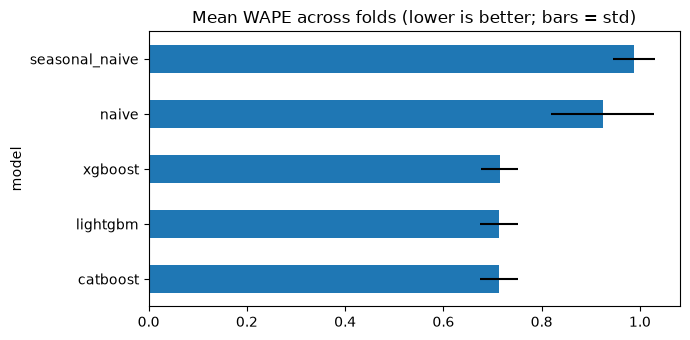

In [6]:
# 4. primary metric with spread across folds
t = table.set_index("model")
ax = t[f"{primary}_mean"].plot.barh(xerr=t[f"{primary}_std"], figsize=(7, 3.5))
ax.set_title(f"Mean {primary.upper()} across folds (lower is better; bars = std)")
plt.tight_layout()
plt.show()

In [7]:
# 5. per fold, so you can see whether one fold drives the result
per_fold = pd.DataFrame({r["model"]: {f["fold"]: f[primary] for f in r["metrics"]["per_fold"]}
                         for r in records})
per_fold.round(3)

,naive,seasonal_naive,catboost,lightgbm,xgboost
0,0.920,1.042,0.759,0.758,0.759
1,1.071,0.976,0.671,0.672,0.672
2,0.823,0.939,0.729,0.731,0.732
3,0.882,0.992,0.694,0.694,0.694


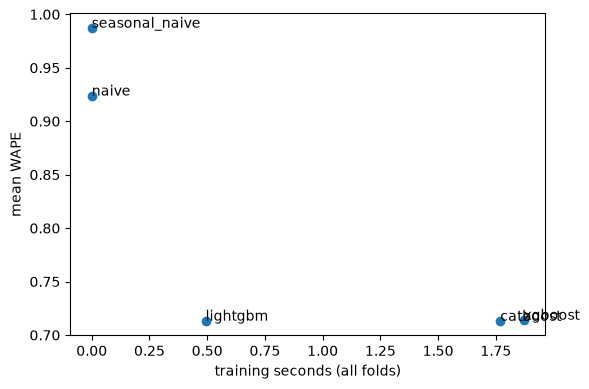

In [8]:
# 6. cost against accuracy
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(t["fit_seconds"], t[f"{primary}_mean"])
for name, row in t.iterrows():
    ax.annotate(name, (row["fit_seconds"], row[f"{primary}_mean"]))
ax.set_xlabel("training seconds (all folds)")
ax.set_ylabel(f"mean {primary.upper()}")
plt.tight_layout()
plt.show()

In [9]:
# 7. neutral summary, computed from the table
lo, hi = t[f"{primary}_mean"].idxmin(), t[f"{primary}_mean"].idxmax()
print(f"Lowest mean {primary.upper()}: {lo} ({t.loc[lo, f'{primary}_mean']:.3f}); "
      f"highest: {hi} ({t.loc[hi, f'{primary}_mean']:.3f}).")
gap = t[f"{primary}_mean"].sort_values().diff().iloc[1]
print(f"Gap between 1st and 2nd: {gap:.3f}; largest fold-to-fold std: "
      f"{t[f'{primary}_std'].max():.3f}.")
print("If the gap is smaller than the std, the ranking is not reliable on this data.")

Lowest mean WAPE: catboost (0.713); highest: seasonal_naive (0.987).
Gap between 1st and 2nd: 0.000; largest fold-to-fold std: 0.106.
If the gap is smaller than the std, the ranking is not reliable on this data.
